# 10 — Causal Machine Learning

## Objective

This notebook investigates a focused causal question within the Monte Carlo MEMS analysis:

> What is the causal effect of stiffness on the natural frequency of the system?

The linearized natural frequency is

$$
f_n
=
\frac{1}{2\pi}
\sqrt{\frac{k}{m}},
$$

where

- $k$ is stiffness,
- $m$ is mass.

A statistical association between stiffness and natural frequency is not, by itself, a causal statement. Causal analysis is based on an intervention concept:

$$
do(k=k^*),
$$

which asks how the outcome would change if stiffness were externally set to a particular value while the other relevant system properties were held fixed.

The Monte Carlo experiment provides a useful controlled environment for this analysis because uncertain physical parameters were generated explicitly.

The notebook will:

- define stiffness as the treatment variable,
- define natural frequency as the outcome,
- account for mass as an important outcome determinant,
- estimate the average causal effect using machine-learning-based residualization,
- construct a physics-based interventional reference,
- compare causal-ML and physics-based estimates.

Temperature is not treated as a causal variable in this analysis because it was sampled in the Monte Carlo experiment but was not connected to the governing dynamics.

In [1]:
# NOTEBOOK SETUP

from pathlib import Path
import sys


# Identify the project root directory.
PROJECT_ROOT = Path.cwd().parent


# Add the project root to Python's import path.
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(
        0,
        str(PROJECT_ROOT),
    )


# Standard scientific Python libraries.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# Machine-learning tools used for nuisance models
# in the causal residualization procedure.
from sklearn.ensemble import RandomForestRegressor


# Project utilities.
from src.utils import (
    data_path,
    results_path,
    figures_path,
    ensure_directory,
)

In [2]:
# LOAD MONTE CARLO RESULTS
monte_carlo_results_path = (
    data_path("monte_carlo")
    / "monte_carlo_results.csv"
)

monte_carlo_results = pd.read_csv(
    monte_carlo_results_path
)


print(
    f"Monte Carlo table shape: "
    f"{monte_carlo_results.shape}"
)

print()

print(
    "Available columns:"
)

for column_name in monte_carlo_results.columns:
    print(
        f"- {column_name}"
    )

Monte Carlo table shape: (1000, 17)

Available columns:
- simulation_id
- mass
- damping
- stiffness
- nonlinear_stiffness
- temperature
- noise_standard_deviation
- sensor_gain
- sensor_bias
- natural_frequency
- damping_ratio
- peak_displacement
- peak_velocity
- peak_acceleration
- peak_measured_signal
- rms_acceleration
- rms_measured_signal


## Causal Problem Definition

The Monte Carlo dataset contains 1000 simulated systems with uncertain physical and measurement parameters.

For the focused causal analysis, the variables are defined as:

- **Treatment:** stiffness $k$
- **Outcome:** natural frequency $f_n$
- **Adjustment variable:** mass $m$

The relevant physical relationship is

$$
f_n
=
\frac{1}{2\pi}
\sqrt{\frac{k}{m}}.
$$

Both stiffness and mass directly influence the natural frequency.

The Monte Carlo simulation sampled these physical parameters independently, so the dataset does not contain a deliberately introduced stiffness–mass confounding mechanism. Consequently, this analysis represents a controlled causal benchmark rather than a difficult observational identification problem.

Other variables such as temperature, sensor noise, sensor gain, and sensor bias are not included in the adjustment set because they do not enter the natural-frequency relationship used in the simulation.

Similarly, response variables such as peak acceleration are not used as adjustment variables because they are downstream dynamical quantities rather than pre-treatment causes of stiffness.

In [3]:
# DEFINE TREATMENT, OUTCOME, AND ADJUSTMENT VARIABLE

causal_stiffness = monte_carlo_results[
    "stiffness"
].to_numpy()

causal_natural_frequency = monte_carlo_results[
    "natural_frequency"
].to_numpy()

causal_mass = monte_carlo_results[
    "mass"
].to_numpy()


print(
    f"Stiffness range: "
    f"{causal_stiffness.min():.6f} "
    f"to {causal_stiffness.max():.6f}"
)

print(
    f"Natural-frequency range: "
    f"{causal_natural_frequency.min():.6f} Hz "
    f"to {causal_natural_frequency.max():.6f} Hz"
)

print(
    f"Mass range: "
    f"{causal_mass.min():.6f} "
    f"to {causal_mass.max():.6f}"
)

print()

print(
    f"Mean stiffness: "
    f"{causal_stiffness.mean():.6f}"
)

print(
    f"Mean natural frequency: "
    f"{causal_natural_frequency.mean():.6f} Hz"
)

print(
    f"Mean mass: "
    f"{causal_mass.mean():.6f}"
)

Stiffness range: 823.159683 to 1144.483738
Natural-frequency range: 4.537185 Hz to 5.446955 Hz
Mass range: 0.892943 to 1.095593

Mean stiffness: 1001.421566
Mean natural frequency: 5.035831 Hz
Mean mass: 1.000282


In [5]:
# CALCULATE THE PHYSICS-BASED CAUSAL REFERENCE

# For
#
# f_n = (1 / 2*pi) * sqrt(k / m)
#
# the local causal derivative with respect to stiffness is
#
# df_n / dk = 1 / (4*pi*sqrt(k*m))

physics_stiffness_effect = (
    1.0
    / (
        4.0
        * np.pi
        * np.sqrt(
            causal_stiffness
            * causal_mass
        )
    )
)


# Average causal effect over the Monte Carlo population.
physics_average_causal_effect = np.mean(
    physics_stiffness_effect
)


# Compare the causal-ML estimate with the physical reference.
causal_effect_absolute_error = abs(
    causal_ml_slope
    - physics_average_causal_effect
)


causal_effect_relative_error = (
    causal_effect_absolute_error
    / physics_average_causal_effect
    * 100.0
)


print(
    f"Physics-based average causal effect: "
    f"{physics_average_causal_effect:.12e} "
    f"Hz per stiffness unit"
)

print(
    f"Causal-ML estimated effect:          "
    f"{causal_ml_slope:.12e} "
    f"Hz per stiffness unit"
)

print()

print(
    f"Absolute effect error: "
    f"{causal_effect_absolute_error:.12e}"
)

print(
    f"Relative effect error: "
    f"{causal_effect_relative_error:.6f}%"
)

Physics-based average causal effect: 2.517660851641e-03 Hz per stiffness unit
Causal-ML estimated effect:          2.521877662185e-03 Hz per stiffness unit

Absolute effect error: 4.216810543895e-06
Relative effect error: 0.167489%


### Causal-ML Estimate versus Physical Reference

The residualization-based causal machine-learning procedure estimated the effect of stiffness on natural frequency as

$$
\hat{\theta}_{\mathrm{ML}}
=
2.52188\times10^{-3}
\ \text{Hz per stiffness unit}.
$$

The corresponding average causal effect calculated directly from the known physical relationship was

$$
\theta_{\mathrm{physics}}
=
2.51766\times10^{-3}
\ \text{Hz per stiffness unit}.
$$

The absolute difference between the two estimates was

$$
4.2168\times10^{-6}
\ \text{Hz per stiffness unit},
$$

corresponding to a relative error of only

$$
0.1675\%.
$$

The positive effect is physically consistent: increasing stiffness increases the natural frequency of the MEMS oscillator.

The close agreement demonstrates that the machine-learning-based residualization procedure recovers the local average stiffness effect very accurately in this controlled Monte Carlo setting.

This should not be interpreted as proof that causal machine learning will automatically recover causal effects from arbitrary observational data. In this simulation, the data-generating mechanism is known, stiffness and mass were sampled independently, and the physical reference effect is available. The experiment therefore serves as a controlled validation of the causal-analysis workflow.

In [6]:
# PHYSICAL INTERVENTION EXPERIMENT

import importlib
import src.causal_analysis

importlib.reload(
    src.causal_analysis
)


from src.causal_analysis import (
    calculate_physics_intervention_effect,
)


# Apply a fixed stiffness intervention.
stiffness_change = 50.0


(
    baseline_intervention_frequency,
    intervened_frequency,
    individual_intervention_effect,
    physics_intervention_average_effect,
) = calculate_physics_intervention_effect(
    stiffness=causal_stiffness,
    mass=causal_mass,
    stiffness_change=stiffness_change,
)


# The causal-ML slope gives a local linear approximation
# for the same intervention.
causal_ml_predicted_intervention_effect = (
    causal_ml_slope
    * stiffness_change
)


# Compare the two intervention estimates.
intervention_absolute_error = abs(
    causal_ml_predicted_intervention_effect
    - physics_intervention_average_effect
)


intervention_relative_error = (
    intervention_absolute_error
    / physics_intervention_average_effect
    * 100.0
)


print(
    f"Applied stiffness intervention: "
    f"+{stiffness_change:.2f}"
)

print()

print(
    f"Physics-based average frequency change: "
    f"{physics_intervention_average_effect:.8f} Hz"
)

print(
    f"Causal-ML predicted frequency change:   "
    f"{causal_ml_predicted_intervention_effect:.8f} Hz"
)

print()

print(
    f"Absolute intervention error: "
    f"{intervention_absolute_error:.8f} Hz"
)

print(
    f"Relative intervention error: "
    f"{intervention_relative_error:.4f}%"
)

Applied stiffness intervention: +50.00

Physics-based average frequency change: 0.12434393 Hz
Causal-ML predicted frequency change:   0.12609388 Hz

Absolute intervention error: 0.00174995 Hz
Relative intervention error: 1.4073%


### Finite Stiffness Intervention

A finite intervention was applied by increasing the stiffness of every Monte Carlo system by

$$
\Delta k = +50.
$$

Using the known physical relationship, the average resulting change in natural frequency was

$$
\Delta f_{n,\mathrm{physics}}
=
0.124344\ \mathrm{Hz}.
$$

The causal-ML estimate predicted

$$
\Delta f_{n,\mathrm{ML}}
=
0.126094\ \mathrm{Hz}.
$$

The absolute difference was

$$
0.001750\ \mathrm{Hz},
$$

corresponding to a relative error of approximately

$$
1.41\%.
$$

The intervention error is larger than the error obtained for the local derivative because the causal-ML coefficient represents a local linear approximation, while the true physical relationship between stiffness and natural frequency is nonlinear.

Nevertheless, the close agreement shows that the estimated causal slope provides a useful approximation of the effect of a realistic finite stiffness intervention within the investigated parameter range.

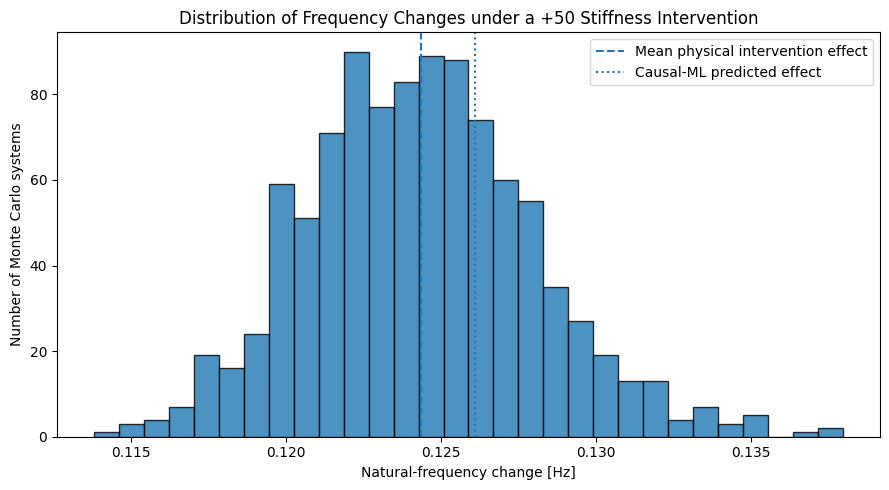

In [7]:
# VISUALIZE INDIVIDUAL INTERVENTION EFFECTS

plt.figure(
    figsize=(9, 5)
)


plt.hist(
    individual_intervention_effect,
    bins=30,
    edgecolor="black",
    alpha=0.8,
)


plt.axvline(
    physics_intervention_average_effect,
    linestyle="--",
    label=(
        "Mean physical intervention effect"
    ),
)


plt.axvline(
    causal_ml_predicted_intervention_effect,
    linestyle=":",
    label=(
        "Causal-ML predicted effect"
    ),
)


plt.xlabel(
    "Natural-frequency change [Hz]"
)

plt.ylabel(
    "Number of Monte Carlo systems"
)

plt.title(
    "Distribution of Frequency Changes "
    "under a +50 Stiffness Intervention"
)

plt.legend()

plt.tight_layout()

plt.show()

### Distribution of Individual Intervention Effects

The finite stiffness intervention does not produce exactly the same natural-frequency change for every Monte Carlo realization.

This occurs because the intervention effect depends on the individual system parameters, particularly the original stiffness and mass.

For the intervention

$$
\Delta k = +50,
$$

the average physics-based frequency change was approximately

$$
0.12434\ \text{Hz}.
$$

The causal-ML approximation predicted

$$
0.12609\ \text{Hz}.
$$

The histogram shows that the individual physical intervention effects are distributed around the average value rather than concentrated at a single point.

The causal-ML prediction lies close to this distribution but slightly above the physical mean, which is consistent with the previously calculated finite-intervention relative error of approximately

$$
1.41\%.
$$

This variation across Monte Carlo systems demonstrates that causal effects can be heterogeneous when uncertain physical parameters vary across the population.

In [11]:
# SAVE CAUSAL ANALYSIS RESULTS

causal_results_directory = results_path(
    "causal_ml"
)

ensure_directory(
    causal_results_directory
)


causal_effect_comparison = pd.DataFrame(
    {
        "quantity": [
            "Causal-ML local effect",
            "Physics average local effect",
            "Local-effect absolute error",
            "Local-effect relative error percent",
            "Physics +50 intervention effect",
            "Causal-ML +50 intervention effect",
            "Intervention absolute error",
            "Intervention relative error percent",
        ],

        "value": [
            causal_ml_slope,
            physics_average_causal_effect,
            causal_effect_absolute_error,
            causal_effect_relative_error,
            physics_intervention_average_effect,
            causal_ml_predicted_intervention_effect,
            intervention_absolute_error,
            intervention_relative_error,
        ],
    }
)


causal_effect_results_path = (
    causal_results_directory
    / "causal_effect_comparison.csv"
)


causal_effect_comparison.to_csv(
    causal_effect_results_path,
    index=False,
)


print(
    "Causal-effect comparison saved to:"
)

print(
    causal_effect_results_path
)

print()

causal_effect_comparison

Causal-effect comparison saved to:
D:\Uni\Mechanical Enginnering Masters\Extra\Data Analysis and Info Engineering\Part II Information Engineering\monte_carlo_mems_sciml\results\causal_ml\causal_effect_comparison.csv



,quantity,value
0,Causal-ML local effect,0.002522
1,Physics average local effect,0.002518
2,Local-effect absolute error,0.000004
3,Local-effect relative error percent,0.167489
4,Physics +50 intervention effect,0.124344
5,Causal-ML +50 intervention effect,0.126094
6,Intervention absolute error,0.001750
7,Intervention relative error percent,1.407348


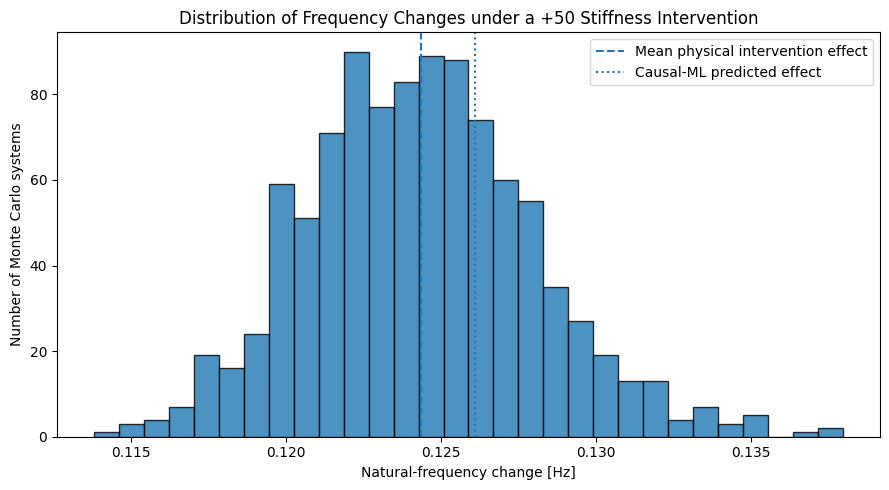

Intervention-effect distribution figure saved to:
D:\Uni\Mechanical Enginnering Masters\Extra\Data Analysis and Info Engineering\Part II Information Engineering\monte_carlo_mems_sciml\figures\causal_ml\stiffness_intervention_effect_distribution.png


In [12]:
# SAVE INTERVENTION-EFFECT DISTRIBUTION FIGURE

causal_figure_directory = figures_path(
    "causal_ml"
)

ensure_directory(
    causal_figure_directory
)


intervention_figure_path = (
    causal_figure_directory
    / "stiffness_intervention_effect_distribution.png"
)


plt.figure(
    figsize=(9, 5)
)


plt.hist(
    individual_intervention_effect,
    bins=30,
    edgecolor="black",
    alpha=0.8,
)


plt.axvline(
    physics_intervention_average_effect,
    linestyle="--",
    label="Mean physical intervention effect",
)


plt.axvline(
    causal_ml_predicted_intervention_effect,
    linestyle=":",
    label="Causal-ML predicted effect",
)


plt.xlabel(
    "Natural-frequency change [Hz]"
)

plt.ylabel(
    "Number of Monte Carlo systems"
)

plt.title(
    "Distribution of Frequency Changes "
    "under a +50 Stiffness Intervention"
)

plt.legend()

plt.tight_layout()


plt.savefig(
    intervention_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()


print(
    "Intervention-effect distribution figure saved to:"
)

print(
    intervention_figure_path
)

In [13]:
# FINAL OUTPUT VALIDATION FOR NOTEBOOK 10

notebook_10_outputs = {
    "causal_effect_comparison":
        causal_effect_results_path,

    "intervention_effect_figure":
        intervention_figure_path,
}


for output_name, output_path in notebook_10_outputs.items():

    print(
        f"{output_name:35s} "
        f"{output_path.exists()}"
    )

causal_effect_comparison            True
intervention_effect_figure          True


# Notebook 10 Summary

This notebook investigated a focused causal question within the Monte Carlo MEMS analysis:

> How does stiffness causally affect the natural frequency of the system?

The treatment variable was stiffness $k$, the outcome was natural frequency $f_n$, and mass $m$ was used as the relevant adjustment variable.

The physical relationship is

$$
f_n
=
\frac{1}{2\pi}
\sqrt{\frac{k}{m}}.
$$

## Residualization-Based Causal Machine Learning

Machine-learning nuisance models were used to remove the variation in stiffness and natural frequency associated with mass.

The residualized causal effect was estimated as

$$
\hat{\theta}_{\mathrm{ML}}
=
2.52188\times10^{-3}
\ \text{Hz per stiffness unit}.
$$

The corresponding average physical local effect was

$$
\theta_{\mathrm{physics}}
=
2.51766\times10^{-3}
\ \text{Hz per stiffness unit}.
$$

The relative error between the causal-ML estimate and the known physical reference was only

$$
0.1675\%.
$$

This shows that the residualization procedure recovered the average local stiffness effect very accurately in the controlled Monte Carlo environment.

## Finite Intervention

A finite intervention was then considered:

$$
do(k=k+50).
$$

The physics-based average increase in natural frequency was

$$
0.124344\ \text{Hz},
$$

while the causal-ML approximation predicted

$$
0.126094\ \text{Hz}.
$$

The resulting relative error was approximately

$$
1.41\%.
$$

The larger error compared with the local-effect comparison is expected because the causal-ML slope is a local linear approximation, whereas the true physical relationship is nonlinear.

## Heterogeneous Intervention Effects

The Monte Carlo analysis also showed that the same stiffness intervention does not produce exactly the same frequency change for every simulated system.

The individual causal effects vary because each Monte Carlo realization has different physical parameters, particularly mass and initial stiffness.

This provides an example of heterogeneous causal effects under physical uncertainty.

## Main Finding

The causal machine-learning estimate was highly consistent with the known physical effect of stiffness on natural frequency.

However, this experiment represents a controlled causal benchmark rather than a difficult observational causal-inference problem. The physical data-generating mechanism is known and the uncertain parameters were independently sampled.

The value of the experiment is therefore to demonstrate how causal machine learning, physical knowledge, and Monte Carlo uncertainty analysis can be combined and quantitatively validated within an engineering system.